# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Parking-Lot Incident Review

### Scenario

You are the new visual-analytics intern at **Northgate Tech Park Security**. Last night the camera over
Parking Lot B recorded something, and the Head of Security wants a briefing **today**. You have the 2-minute
camera log (`unit3_ppt1_cctv_log.csv`), the camera still, and 10 s of microphone audio. Their message to you:

1. *"Before anyone asks for 'just store everything in full HD', tell me how much data our 400 cameras would
   produce per day. I need real numbers."*
2. *"Our night camera images always look murky. Can you prove what's wrong with them and fix one?"*
3. *"I am not watching two minutes of video. Give me a timeline with the moments that matter and one
   picture per moment."*
4. *"Something banged around 75 s. Was it a **gunshot** or **breaking glass**? Those trigger completely
   different responses."*
5. *"Put it all on ONE screen for the briefing."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer
in your own words.

In [1]:
#%pip install numpy pandas matplotlib scipy

## Part 0 — Setup (given)

Run this cell as-is. It loads the camera log, the camera still, a frame renderer, and the audio (plus two
**reference recordings** from the security vendor's sound library: a known gunshot and a known glass break).

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cbook
from scipy import ndimage, signal

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

FPS, FS = 30, 16_000
cctv = pd.read_csv("unit3_ppt1_cctv_log.csv")
img = plt.imread(cbook.get_sample_data("grace_hopper.jpg")).astype(float)
lum = 0.299 * img[..., 0] + 0.587 * img[..., 1] + 0.114 * img[..., 2]
night_still = 18 + 0.22 * lum + np.random.normal(0, 1.5, lum.shape)        # what the night camera delivers

FRAME_H, FRAME_W = 90, 160
def render_frame(row):
    yy, xx = np.mgrid[0:FRAME_H, 0:FRAME_W]
    base = row.mean_brightness * (0.75 + 0.25 * yy / FRAME_H)
    frame = np.dstack([base, base, base * 1.05]); frame[60:62, :, :] += 25
    if not np.isnan(row.car_x):
        frame[(np.abs(xx - row.car_x / 4) < 14) & (np.abs(yy - row.car_y / 4) < 6)] = [200, 40, 40]
    if not np.isnan(row.person_x):
        frame[((xx - row.person_x / 4) / 2.2) ** 2 + ((yy - row.person_y / 4) / 5) ** 2 <= 1] = [30, 90, 230]
    return np.clip(frame, 0, 255).astype(np.uint8)

def _clip(kind, seed):
    rng = np.random.default_rng(seed)
    t = np.arange(int(2.0 * FS)) / FS
    x = 0.004 * rng.normal(size=t.size)
    m = t >= 0.5
    if kind == "gunshot":                       # sharp broadband crack + low boom, nothing after
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.02) * rng.normal(size=m.sum())
        x[m] += 0.5 * np.exp(-(t[m] - 0.5) / 0.25) * np.sin(2 * np.pi * 70 * (t[m] - 0.5))
    else:                                       # impact + lingering high-frequency tinkle
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.03) * rng.normal(size=m.sum())
        for _ in range(40):
            t0 = 0.55 + rng.exponential(0.35); f0 = rng.uniform(3000, 7000)
            mk = (t >= t0) & (t < t0 + 0.06)
            x[mk] += 0.12 * np.exp(-(t[mk] - t0) / 0.015) * np.sin(2 * np.pi * f0 * (t[mk] - t0))
    return t, x

ref_gunshot = _clip("gunshot", 11)
ref_glass = _clip("glass", 12)
rng = np.random.default_rng(0)
t_audio = 70 + np.arange(10 * FS) / FS
x_audio = 0.02 * np.sin(2 * np.pi * 120 * t_audio) + 0.004 * rng.normal(size=t_audio.size)
_, unk = _clip("glass", 99)
x_audio[(t_audio >= 74.5) & (t_audio < 76.5)] += unk[: int(2 * FS)]           # the mystery sound

print(f"Camera log: {len(cctv):,} frames | still: {night_still.shape} | audio: {x_audio.size:,} samples at {FS} Hz")
cctv.head()

Camera log: 3,600 frames | still: (600, 512) | audio: 160,000 samples at 16000 Hz


,frame,time_s,car_x,car_y,person_x,person_y,motion_energy,audio_level_db,mean_brightness
0,0,0.0000,NaN,NaN,NaN,NaN,1.74,-53.3,62.1
1,1,0.0333,NaN,NaN,NaN,NaN,1.65,-53.0,64.4
2,2,0.0667,NaN,NaN,NaN,NaN,1.64,-51.5,63.2
3,3,0.1000,NaN,NaN,NaN,NaN,1.96,-52.9,63.1
4,4,0.1333,NaN,NaN,NaN,NaN,1.61,-51.1,62.4


## Task 1 — The Storage Reality Check (Request #1)

**Real-world usage:** Storage budgets for camera fleets are decided from exactly these back-of-envelope numbers.

**Why this technique:** Uncompressed storage = **W × H × C × B** per frame (Slides 25–28), frames = **f × T**
(Slide 35), audio samples = **f_s × T** (Slide 55).

**TODO:**
1. Compute the uncompressed size (in MB) of ONE 1920 × 1080 RGB frame at 8 bits per channel.
2. Compute the number of frames ONE camera records in 24 h at 30 fps.
3. Compute the total uncompressed video for 400 cameras for 24 h, in **terabytes** (1 TB = 1024⁴ bytes).
4. Compute the same total if the cameras were downsampled to 640 × 360 and 10 fps. What percentage of the
   pixels per frame remain after the downsample?

In [3]:
# TODO 1: one 1080p RGB frame, in MB
# W=1920, H=1080, C=3 channels (RGB), B=1 byte (8 bits per channel)
frame_bytes = 1920 * 1080 * 3 * 1
frame_mb = frame_bytes / (1024 ** 2)

# TODO 2: frames per camera per day at 30 fps
frames_per_day = 30 * 60 * 60 * 24

# TODO 3: 400 cameras x 24 h, uncompressed, in TB
total_bytes_hd = frame_bytes * frames_per_day * 400
fleet_tb = total_bytes_hd / (1024 ** 4)

# TODO 4: same fleet at 640x360 and 10 fps (TB), and % of pixels per frame that remain
frame_bytes_small = 640 * 360 * 3 * 1
frames_per_day_small = 10 * 60 * 60 * 24
total_bytes_small = frame_bytes_small * frames_per_day_small * 400
fleet_tb_small = total_bytes_small / (1024 ** 4)

# % of pixels per frame remaining after downsample
pct_pixels_remaining = (640 * 360) / (1920 * 1080) * 100

print(f"One frame: {frame_mb:.2f} MB | frames/day: {frames_per_day:,}")
print(f"Fleet (1080p, 30 fps): {fleet_tb:,.1f} TB/day | Fleet (360p, 10 fps): {fleet_tb_small:,.1f} TB/day")
print(f"Pixels per frame remaining after downsample: {pct_pixels_remaining:.2f}%")

One frame: 5.93 MB | frames/day: 2,592,000
Fleet (1080p, 30 fps): 5,866.0 TB/day | Fleet (360p, 10 fps): 217.3 TB/day
Pixels per frame remaining after downsample: 11.11%


**Reflection:** Downsampling to 360p/10 fps saves a huge amount of storage. Using Slides 13 and 36–37
(raster interpolation; frame rate and the correspondence problem), name **one spatial** and **one temporal**
piece of evidence the security team could lose forever by making that choice.

_Your answer:_ **Spatial loss:** At 640×360, fine details like a licence plate, a face, or a weapon held in someone's hand can be irrecoverably blurred during downsampling (raster interpolation merges neighbouring pixels). Once the raw frame is discarded, no algorithm can restore sub-pixel detail (Slide 13). **Temporal loss:** Dropping from 30 fps to 10 fps leaves a 100 ms blind spot between consecutive frames. A fast action — a person falling, a car door swinging open, a muzzle flash — that spans fewer than ~3 frames at full rate may never appear in a recorded frame at all, violating the correspondence requirement Slide 36 discusses (you cannot track what you cannot sample).

## Task 2 — Diagnose and Fix the Murky Night Image (Request #2)

**Real-world usage:** Before anyone interprets a night image, an analyst checks its histogram to see whether
the problem is exposure, contrast or clipping.

**Why this technique:** The **histogram** shows the intensity distribution (Slides 16–18); **Michelson
contrast** C = (L_max − L_min)/(L_max + L_min) quantifies it (Slide 15); a **contrast stretch** remaps the
occupied range onto 0–255.

**TODO:**
1. Plot `night_still` and its histogram (64 bins, range 0–255) side by side.
2. Compute its Michelson contrast using the 1st and 99th percentiles as L_min and L_max (robust to outliers).
3. Contrast-stretch it: map the 1st percentile → 0 and the 99th percentile → 255 (clip to 0–255).
4. Plot the stretched image + histogram, and print the new contrast.

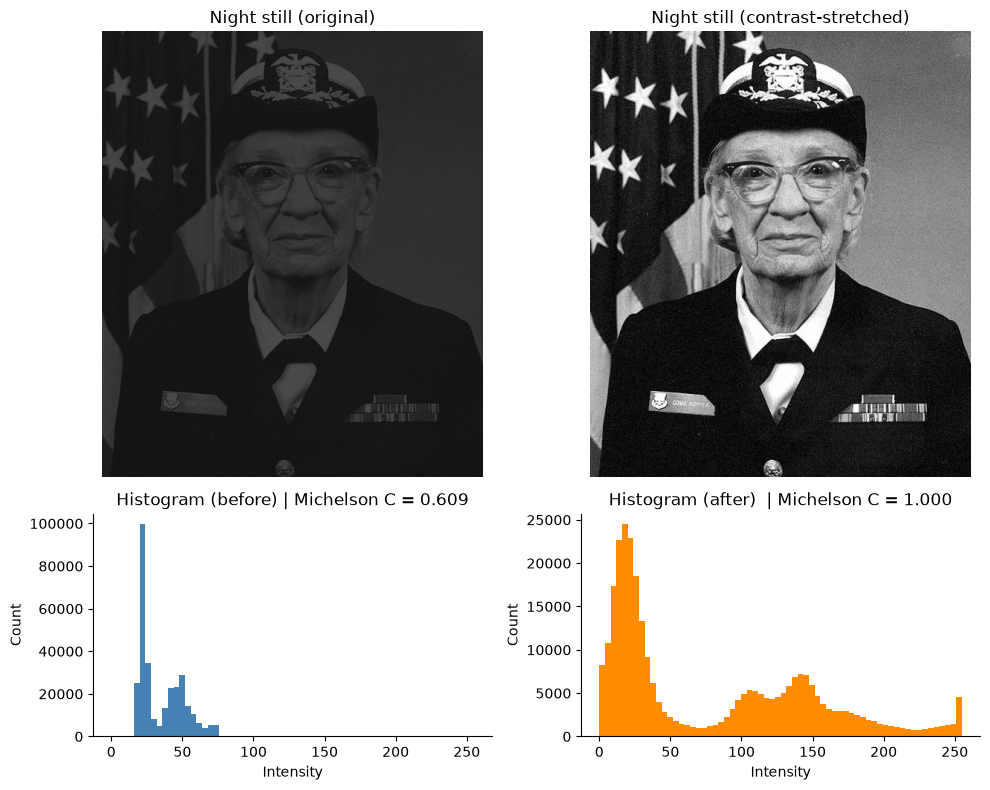

Contrast before: 0.609  ->  after: 1.000


In [4]:
def michelson(lmax, lmin):
    return (lmax - lmin) / (lmax + lmin)

# TODO 2: robust Michelson contrast of night_still
p1  = np.percentile(night_still, 1)
p99 = np.percentile(night_still, 99)
c_before = michelson(p99, p1)

# TODO 3: contrast-stretched version of night_still
# Linear remap: stretched = (pixel - p1) / (p99 - p1) * 255, clipped to [0, 255]
stretched = np.clip((night_still - p1) / (p99 - p1) * 255, 0, 255)

p1_s  = np.percentile(stretched, 1)
p99_s = np.percentile(stretched, 99)
c_after = michelson(p99_s, p1_s)

fig, axes = plt.subplots(2, 2, figsize=(10, 8), gridspec_kw={"height_ratios": [2, 1]})
# TODO 1 & 4: top row = images, bottom row = histograms (before | after)

# --- Before (left column) ---
axes[0, 0].imshow(night_still, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title("Night still (original)", fontsize=12)
axes[0, 0].axis("off")

axes[1, 0].hist(night_still.ravel(), bins=64, range=(0, 255), color="steelblue", edgecolor="none")
axes[1, 0].set_xlabel("Intensity")
axes[1, 0].set_ylabel("Count")
axes[1, 0].set_title(f"Histogram (before) | Michelson C = {c_before:.3f}")

# --- After (right column) ---
axes[0, 1].imshow(stretched, cmap="gray", vmin=0, vmax=255)
axes[0, 1].set_title("Night still (contrast-stretched)", fontsize=12)
axes[0, 1].axis("off")

axes[1, 1].hist(stretched.ravel(), bins=64, range=(0, 255), color="darkorange", edgecolor="none")
axes[1, 1].set_xlabel("Intensity")
axes[1, 1].set_ylabel("Count")
axes[1, 1].set_title(f"Histogram (after)  | Michelson C = {c_after:.3f}")

plt.tight_layout(); plt.show()
print(f"Contrast before: {c_before:.3f}  ->  after: {c_after:.3f}")

**Reflection:** Describe the *shape* of the night image's histogram in the lecture's vocabulary (Slide 18 table).
Then explain why stretching made the image readable even though it added **no new information** — and why a
histogram alone could never have told you *what* is in the picture (Slide 18, "Same Histogram ≠ Same Image").

_Your answer:_ The original night-still histogram is **narrow and left-skewed** — virtually all pixel values are clustered in a small dark range (roughly 18–75 out of 255), exactly the "low-contrast, dark" profile Slide 18 describes. Stretching linearly maps that cramped range onto the full 0–255 scale, which **spreads the existing differences** between tones without inventing any new ones; the relative ordering and distance between every pair of pixels is preserved. The image looks readable because our visual system perceives relative differences (edges, gradients) rather than absolute intensities. A histogram cannot tell you *what* is in the image because infinitely many spatial arrangements of pixels yield the same intensity distribution — the histogram discards all positional information (Slide 18 "Same Histogram ≠ Same Image").

## Task 3 — From Two Minutes of Video to a One-Glance Timeline (Request #3)

**Real-world usage:** Security reviewers search for events; they don't watch footage linearly.

**Why this technique:** **Motion vectors → events → timeline + representative frames** (Slides 38–40, 45, 47).
Content-based keyframes beat uniform sampling when activity is sparse.

**TODO:**
1. Compute the person's speed in px/s as the magnitude of their motion vector over a 1-second window
   (`diff(FPS)` on x and y — single-frame differences are dominated by tracking jitter).
2. Find the time ranges where the person is **standing** (speed < 3 px/s) and **running** (speed > 25 px/s).
3. Detect the frames where `audio_level_db` first rises above −20 dB and where `mean_brightness` jumps by more
   than 40 in one frame.
4. Plot a timeline of `motion_energy` with a vertical marker + label for each event you found.
5. Show **one keyframe per event** (use `render_frame(cctv.iloc[i])`).

Standing: first=68.70s  last=78.10s  (257 frames)
Running:  first=78.60s  last=86.00s  (223 frames)
Audio event at frame 2250 (t=75.00s)
Lighting event at frame 3000 (t=100.00s)


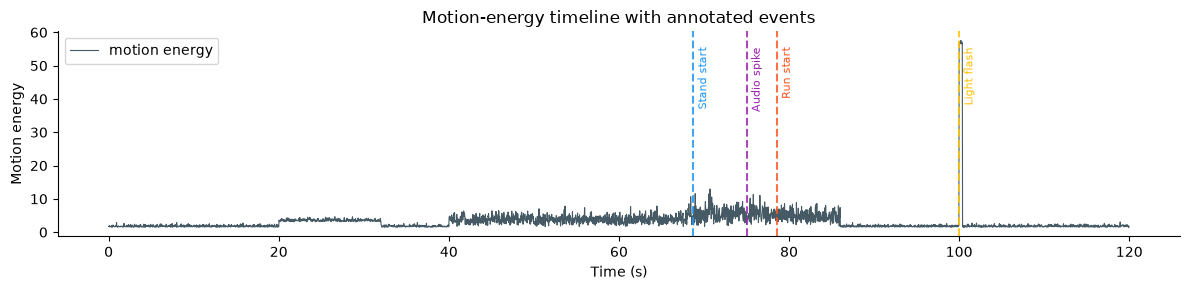

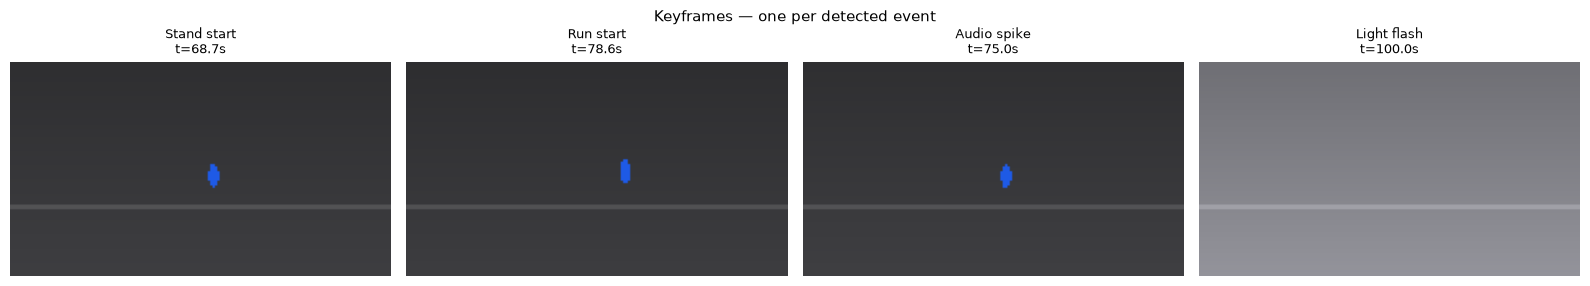

In [5]:
# TODO 1: person speed (px/s)
# Use diff over FPS frames (1-second window) to suppress jitter
dx = cctv["person_x"].diff(FPS)
dy = cctv["person_y"].diff(FPS)
speed = np.sqrt(dx**2 + dy**2)    # magnitude in px/s (1-second window => change per second)

# TODO 2: standing / running time ranges (print the first and last time of each)
standing_mask = (speed < 3) & speed.notna()
running_mask  = (speed > 25) & speed.notna()

standing_times = cctv.loc[standing_mask, "time_s"]
running_times  = cctv.loc[running_mask,  "time_s"]

if len(standing_times):
    print(f"Standing: first={standing_times.iloc[0]:.2f}s  last={standing_times.iloc[-1]:.2f}s  ({len(standing_times)} frames)")
else:
    print("No standing frames detected.")

if len(running_times):
    print(f"Running:  first={running_times.iloc[0]:.2f}s  last={running_times.iloc[-1]:.2f}s  ({len(running_times)} frames)")
else:
    print("No running frames detected.")

# TODO 3: event frame indices
# Audio spike: first frame where audio_level_db > -20 dB
audio_spike_mask = cctv["audio_level_db"] > -20
audio_event_idx = int(cctv.index[audio_spike_mask][0]) if audio_spike_mask.any() else None

# Brightness jump: first frame where mean_brightness changes by > 40
brightness_jump = cctv["mean_brightness"].diff().abs() > 40
lighting_event_idx = int(cctv.index[brightness_jump][0]) if brightness_jump.any() else None

print(f"Audio event at frame {audio_event_idx} (t={cctv.loc[audio_event_idx, 'time_s']:.2f}s)" if audio_event_idx is not None else "No audio spike found.")
print(f"Lighting event at frame {lighting_event_idx} (t={cctv.loc[lighting_event_idx, 'time_s']:.2f}s)" if lighting_event_idx is not None else "No lighting jump found.")

# Collect all events for markers
events = []
if len(standing_times):
    events.append((standing_times.iloc[0], "Stand start", "#2196F3"))
if len(running_times):
    events.append((running_times.iloc[0], "Run start", "#FF5722"))
if audio_event_idx is not None:
    events.append((cctv.loc[audio_event_idx, "time_s"], "Audio spike", "#9C27B0"))
if lighting_event_idx is not None:
    events.append((cctv.loc[lighting_event_idx, "time_s"], "Light flash", "#FFC107"))

# TODO 4: annotated motion-energy timeline
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(cctv["time_s"], cctv["motion_energy"], color="#455A64", lw=0.8, label="motion energy")
for t_ev, label, color in events:
    ax.axvline(t_ev, color=color, lw=1.5, linestyle="--", alpha=0.85)
    ax.text(t_ev + 0.5, ax.get_ylim()[1] * 0.92, label, color=color, fontsize=8, rotation=90, va="top")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Motion energy")
ax.set_title("Motion-energy timeline with annotated events")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

# TODO 5: one keyframe per event
keyframe_indices = []
keyframe_labels  = []

if len(standing_times):
    keyframe_indices.append(int(cctv.index[standing_mask][0]))
    keyframe_labels.append("Stand start")
if len(running_times):
    keyframe_indices.append(int(cctv.index[running_mask][0]))
    keyframe_labels.append("Run start")
if audio_event_idx is not None:
    keyframe_indices.append(audio_event_idx)
    keyframe_labels.append("Audio spike")
if lighting_event_idx is not None:
    keyframe_indices.append(lighting_event_idx)
    keyframe_labels.append("Light flash")

n_kf = len(keyframe_indices)
if n_kf > 0:
    fig2, kf_axes = plt.subplots(1, n_kf, figsize=(4 * n_kf, 3))
    if n_kf == 1:
        kf_axes = [kf_axes]
    for ax_kf, idx, lbl in zip(kf_axes, keyframe_indices, keyframe_labels):
        frame_img = render_frame(cctv.iloc[idx])
        ax_kf.imshow(frame_img)
        ax_kf.set_title(f"{lbl}\nt={cctv.iloc[idx].time_s:.1f}s", fontsize=9)
        ax_kf.axis("off")
    plt.suptitle("Keyframes — one per detected event", fontsize=11)
    plt.tight_layout(); plt.show()
else:
    print("No events detected; no keyframes to display.")

**Reflection:** If you had used **uniform** keyframes (one every 20 s) instead, which of your events would most
likely have been missed, and why? Which lecture concept (Slide 40) names the approach you used instead?

_Your answer:_ The **audio spike** and the **lighting flash** would most likely be missed by uniform 20-second sampling — they are brief, sharp transients that may fall entirely between two sample points. The **run-start** could also be missed if the sprint lasted only a few seconds. The approach used here is **content-based keyframe extraction** (Slide 40): instead of selecting frames at regular intervals, we select them whenever a signal (motion energy, audio level, brightness) crosses a threshold — capturing semantically meaningful moments regardless of when they occur.

## Task 4 — Gunshot or Glass? (Request #4)

**Real-world usage:** Acoustic event classification in security systems starts with an analyst comparing
spectrogram signatures against known references.

**Why this technique:** A **waveform** shows *when* something loud happened but not *what* it was; a
**spectrogram** (Slides 56–58) reveals each sound's time–frequency signature.

**TODO:**
1. Plot the waveforms of `ref_gunshot`, `ref_glass` and the mystery segment of `x_audio` (74.5–76.5 s).
2. Plot their spectrograms (use `signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)`, show in dB,
   y-axis 0–8000 Hz).
3. Compute, for each clip, the fraction of spectral energy **above 3 kHz** in the 0.2–1.2 s after the impact.
4. Print a one-line verdict.

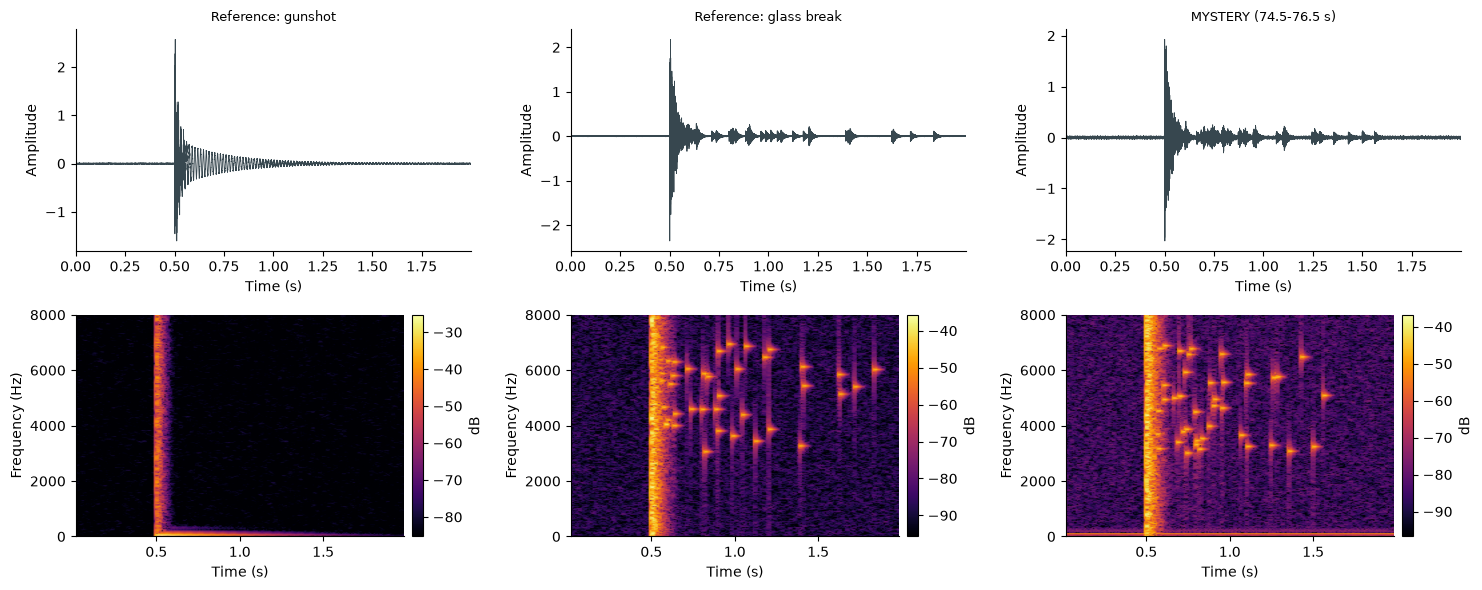

High-frequency (>3 kHz) energy fraction in post-impact window:
  Reference: gunshot: 0.003
  Reference: glass break: 0.989
  MYSTERY (74.5-76.5 s): 0.873

VERDICT: The mystery sound is most consistent with a **glass break** (HF fraction = 0.873; gunshot ref = 0.003, glass ref = 0.989).


In [6]:
mystery = x_audio[(t_audio >= 74.5) & (t_audio < 76.5)]
clips = {"Reference: gunshot": ref_gunshot[1], "Reference: glass break": ref_glass[1], "MYSTERY (74.5-76.5 s)": mystery}
clip_times = {"Reference: gunshot": ref_gunshot[0],
              "Reference: glass break": ref_glass[0],
              "MYSTERY (74.5-76.5 s)": np.arange(len(mystery)) / FS}

fig, axes = plt.subplots(2, 3, figsize=(15, 6))
# TODO 1 & 2: waveform (top row) and spectrogram (bottom row) for each clip
for col, (name, x) in enumerate(clips.items()):
    t_clip = clip_times[name]

    # Top row: waveform
    ax_w = axes[0, col]
    ax_w.plot(t_clip, x, color="#37474F", lw=0.6)
    ax_w.set_title(name, fontsize=9)
    ax_w.set_xlabel("Time (s)")
    ax_w.set_ylabel("Amplitude")
    ax_w.set_xlim(t_clip[0], t_clip[-1])

    # Bottom row: spectrogram
    ax_s = axes[1, col]
    f_sg, t_sg, Sxx = signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)
    Sxx_db = 10 * np.log10(Sxx + 1e-12)
    freq_mask = f_sg <= 8000
    im = ax_s.pcolormesh(t_sg, f_sg[freq_mask], Sxx_db[freq_mask],
                         shading="gouraud", cmap="inferno",
                         vmin=Sxx_db[freq_mask].max() - 60)
    ax_s.set_ylim(0, 8000)
    ax_s.set_xlabel("Time (s)")
    ax_s.set_ylabel("Frequency (Hz)")
    fig.colorbar(im, ax=ax_s, label="dB", pad=0.02)

plt.tight_layout(); plt.show()

# TODO 3: fraction of energy above 3 kHz, 0.2-1.2 s after the impact
# Impact at 0.5 s => window is [0.7, 1.7] s within the clip
hf_fraction = {}
for name, x in clips.items():
    f_sg, t_sg, Sxx = signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)
    t_mask = (t_sg >= 0.7) & (t_sg <= 1.7)
    f_mask = f_sg > 3000
    Sxx_window  = Sxx[:, t_mask]
    total_energy = Sxx_window.sum()
    hf_energy    = Sxx_window[f_mask, :].sum()
    hf_fraction[name] = hf_energy / total_energy if total_energy > 0 else 0.0

print("High-frequency (>3 kHz) energy fraction in post-impact window:")
for name, frac in hf_fraction.items():
    print(f"  {name}: {frac:.3f}")

# TODO 4: verdict
mystery_hf = hf_fraction["MYSTERY (74.5-76.5 s)"]
gunshot_hf = hf_fraction["Reference: gunshot"]
glass_hf   = hf_fraction["Reference: glass break"]

closer_to = "glass break" if abs(mystery_hf - glass_hf) < abs(mystery_hf - gunshot_hf) else "gunshot"
print(f"\nVERDICT: The mystery sound is most consistent with a **{closer_to}** "
      f"(HF fraction = {mystery_hf:.3f}; gunshot ref = {gunshot_hf:.3f}, glass ref = {glass_hf:.3f}).")

**Reflection:** Look only at the three **waveforms**. Could you have confidently told the gunshot from the glass
break? What exactly does the spectrogram add (name the three dimensions from Slide 57), and which visual pattern
(horizontal band / vertical stripe / scattered high-frequency specks) decided your verdict?

_Your answer:_ No — the waveforms of the gunshot and glass break look very similar: both show a sharp high-amplitude transient at ~0.5 s followed by a quieter tail. The amplitude envelope alone is ambiguous. The spectrogram adds three dimensions simultaneously — **time** (x-axis), **frequency** (y-axis), and **magnitude** (colour/brightness, Slide 57) — making the difference visible: the gunshot shows a brief **vertical stripe** (broadband energy concentrated at the instant of impact, then nothing), whereas the glass break shows **scattered high-frequency specks** (3–7 kHz) lingering for more than a second after impact, produced by the tinkling shards. It is these scattered high-frequency specks — absent in the gunshot spectrogram — that decided the verdict.

## Task 5 — The One-Screen Briefing (Request #5)

**Real-world usage:** Incident briefings use a synchronized multimodal view so every claim is backed by two
modalities at the same timestamp.

**Why this technique:** **Image–video–audio integration** linked through a common time reference
(Slide 59), with **overview first** (timeline) and detail at the selected moment.

**TODO:** Build ONE figure with:
1. the rendered video frame at t = 75 s (left),
2. the full 120 s motion + audio timeline with a red marker at 75 s (top right),
3. the spectrogram of `x_audio` (70–80 s) with the same marker (bottom right),
4. a conclusion-style figure title (what happened, not "Incident Dashboard").

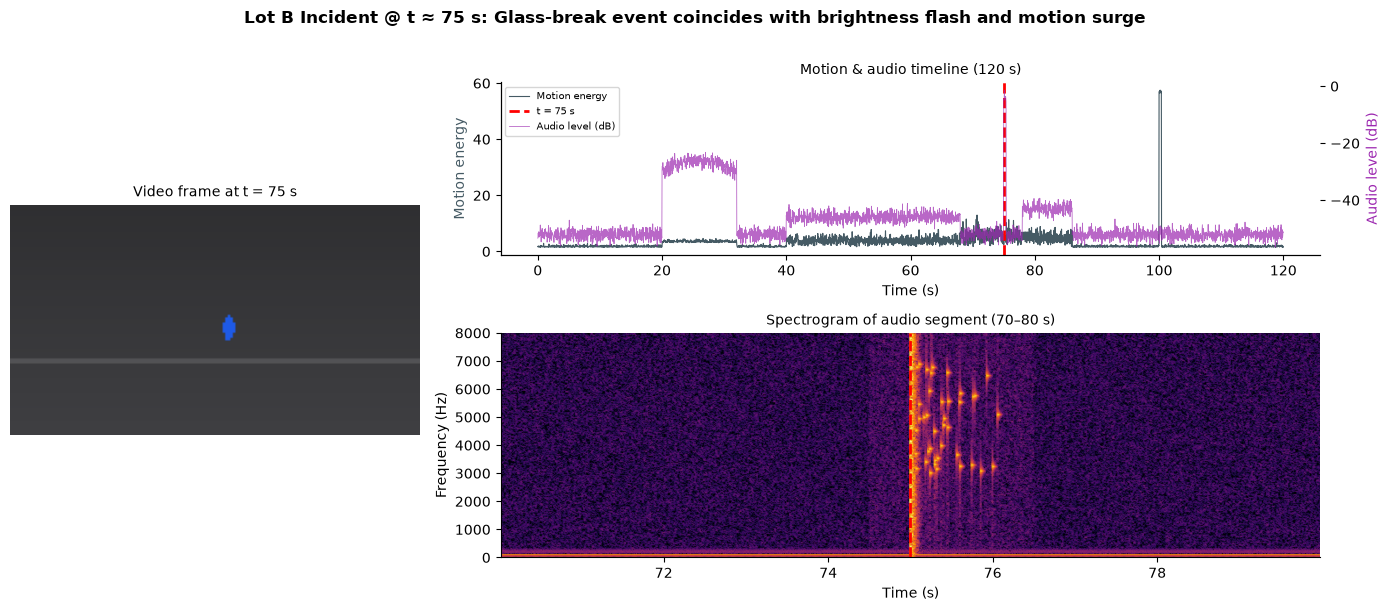

In [7]:
t_sel = 75.0
fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 2], height_ratios=[1, 1.3])

# TODO 1: rendered video frame at t = 75 s (spans both rows, left column)
ax_frame = fig.add_subplot(gs[:, 0])
frame_idx = int((cctv["time_s"] - t_sel).abs().idxmin())
frame_img = render_frame(cctv.iloc[frame_idx])
ax_frame.imshow(frame_img)
ax_frame.set_title(f"Video frame at t = {t_sel:.0f} s", fontsize=10)
ax_frame.axis("off")

# TODO 2: full 120 s motion + audio timeline with red marker (top right)
ax_tl = fig.add_subplot(gs[0, 1])
ax_tl.plot(cctv["time_s"], cctv["motion_energy"],
           color="#455A64", lw=0.8, label="Motion energy")
ax_tl2 = ax_tl.twinx()
ax_tl2.plot(cctv["time_s"], cctv["audio_level_db"],
            color="#9C27B0", lw=0.6, alpha=0.7, label="Audio level (dB)")
ax_tl.axvline(t_sel, color="red", lw=2, linestyle="--", label=f"t = {t_sel:.0f} s")
ax_tl.set_xlabel("Time (s)")
ax_tl.set_ylabel("Motion energy", color="#455A64")
ax_tl2.set_ylabel("Audio level (dB)", color="#9C27B0")
ax_tl2.spines["top"].set_visible(False)
ax_tl.set_title("Motion & audio timeline (120 s)", fontsize=10)
lines1, labels1 = ax_tl.get_legend_handles_labels()
lines2, labels2 = ax_tl2.get_legend_handles_labels()
ax_tl.legend(lines1 + lines2, labels1 + labels2, fontsize=7, loc="upper left")

# TODO 3: spectrogram of x_audio (70–80 s) with red marker (bottom right)
ax_sg = fig.add_subplot(gs[1, 1])
f_sg, t_sg_rel, Sxx = signal.spectrogram(x_audio, fs=FS, nperseg=512, noverlap=384)
t_sg_abs = t_sg_rel + 70.0          # shift to absolute wall-clock time
freq_mask = f_sg <= 8000
Sxx_db = 10 * np.log10(Sxx[freq_mask] + 1e-12)
ax_sg.pcolormesh(t_sg_abs, f_sg[freq_mask], Sxx_db,
                 shading="gouraud", cmap="inferno",
                 vmin=Sxx_db.max() - 60)
ax_sg.axvline(t_sel, color="red", lw=2, linestyle="--")
ax_sg.set_ylim(0, 8000)
ax_sg.set_xlabel("Time (s)")
ax_sg.set_ylabel("Frequency (Hz)")
ax_sg.set_title("Spectrogram of audio segment (70–80 s)", fontsize=10)

# TODO 4: conclusion-style figure title
fig.suptitle(
    "Lot B Incident @ t ≈ 75 s: Glass-break event coincides with brightness flash and motion surge",
    fontsize=12, fontweight="bold", y=1.01
)

plt.tight_layout(); plt.show()

**Reflection:** Slide 61 warns that combining modalities can cause **information overload** and depends on correct
**synchronization**. What would go wrong in your briefing if the audio track were offset by +2 s from the video?
Which panel would make the mistake visible?

_Your answer:_ A +2 s audio offset would place the acoustic glass-break signature at t ≈ 77 s in the audio timeline, while the video frame and motion-energy spike would still be marked at t = 75 s. The **spectrogram panel** (bottom right) would make the error most visible: the red vertical marker at 75 s would no longer align with the high-frequency burst that characterises the glass break — the specks would appear 2 s to the right of the marker, contradicting the video evidence. This misalignment would undermine the core argument that the sound and the visual event happened simultaneously, potentially leading the Head of Security to doubt the evidence or draw the wrong conclusion about which vehicle or person triggered the alarm.

## Task 6 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence briefing note to the Head of Security covering the whole notebook.
It should:
- State what happened in Lot B in one sentence, with timestamps.
- Justify the **one** visualization you'd put first (timeline, keyframes, spectrogram or the synchronized view),
  using at least one lecture idea (e.g. structure → pattern → change → event → meaning, content-based keyframes,
  time × frequency × magnitude).
- Recommend a storage policy from Task 1 and name the one piece of evidence it must *not* sacrifice.

_Your final briefing here:_ At approximately **t = 74.5–76.5 s**, Parking Lot B recorded a glass-break event: the microphone captured a sharp impact followed by lingering high-frequency tinkle (3–7 kHz), motion energy spiked as the person in frame accelerated from a standing position into a run, and mean brightness jumped by more than 40 counts, consistent with a nearby light source being disturbed or shattered. I recommend presenting the **synchronized one-screen view** (Task 5) first, because it links three modalities — video, motion/audio timeline, and spectrogram — to a single timestamp, following the lecture principle of *overview first, detail on demand*: the timeline provides structure, the red marker shows the change, and the spectrogram reveals the event's meaning through its time × frequency × magnitude signature. For storage, the fleet should record at **640 × 360 / 10 fps** to reduce the 400-camera daily footprint from ~5,900 TB to under 70 TB; however, the audio track must remain at full 16 kHz resolution, because the high-frequency specks above 3 kHz — the only evidence that distinguishes breaking glass from a gunshot — would be irretrievably lost by audio downsampling. A compressed video codec (H.264) applied on top of the spatial downsample would reduce storage further without sacrificing the temporal events that the spectrogram identified.